
# Predicting Overwatch League Match Winners Using SEMMA

**CMPE 255 - Data Mining**

## Project Objective

This project applies the SEMMA data mining methodology to historical Overwatch League match data.

The goal is to examine team performance and predict match winners using information available before each match.

The five SEMMA phases are:
1. Sample
2. Explore
3. Modify
4. Model
5. Assess

**Dataset:** Overwatch League Head-to-Head Statistics with Odds (Kaggle)

**Source:** https://www.kaggle.com/datasets/mdabbert/overwatch-league-with-odds

**Important:** This project uses historical match data. It does not predict outcomes in the current Overwatch competitive environment.



## 1. Sample

### Objective

The Sample phase identifies the dataset and determines which records are suitable for analysis.

This project uses historical Overwatch League match records. Each row represents one match between two teams.

We will inspect the dataset size, column names, match dates, participating teams, and target distribution before deciding how to prepare the data.

Because the dataset contains only 715 matches, we will initially retain all available records rather than take a smaller random sample.


In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

df = pd.read_csv("owl-with-odds.csv")

print("Dataset loaded successfully")
print("Dataset shape:", df.shape)
display(df.head())


Saving owl-with-odds.csv to owl-with-odds (1).csv
Dataset loaded successfully
Dataset shape: (715, 58)


,Unnamed: 0.1,Unnamed: 0,id,team_one,team_two,stage,winner,date,corona_virus_isolation,t1_wins_season,...,t2_win_percent_last_20,t1_place_last_season,t2_place_last_season,t1_wins_vs_t2,t1_losses_vs_t2,t1_matches_vs_t2,t1_win_percent_vs_t2,winner_label,t1_odds,t2_odds
0,0,0,10223,Los Angeles Valiant,San Francisco Shock,Overwatch League - Stage 1,Los Angeles Valiant,1/11/2018,False,0.0,...,NaN,NaN,NaN,0,0,0,NaN,0,NaN,NaN
1,1,1,10224,Los Angeles Gladiators,Shanghai Dragons,Overwatch League - Stage 1,Los Angeles Gladiators,1/11/2018,False,0.0,...,NaN,NaN,NaN,0,0,0,NaN,0,-370,276
2,2,2,10225,Seoul Dynasty,Dallas Fuel,Overwatch League - Stage 1,Seoul Dynasty,1/11/2018,False,0.0,...,NaN,NaN,NaN,0,0,0,NaN,0,-588,413
3,3,3,10226,Florida Mayhem,London Spitfire,Overwatch League - Stage 1,London Spitfire,1/11/2018,False,0.0,...,NaN,NaN,NaN,0,0,0,NaN,1,652,-1667
4,4,4,10227,Houston Outlaws,Philadelphia Fusion,Overwatch League - Stage 1,Philadelphia Fusion,1/11/2018,False,0.0,...,NaN,NaN,NaN,0,0,0,NaN,1,-161,143


In [2]:

print("Number of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes.value_counts())

print("\nMissing values (top 10):")
display(df.isna().sum().sort_values(ascending=False).head(10))


Number of rows: 715
Number of columns: 58

Column names:
['Unnamed: 0.1', 'Unnamed: 0', 'id', 'team_one', 'team_two', 'stage', 'winner', 'date', 'corona_virus_isolation', 't1_wins_season', 't1_losses_season', 't2_wins_season', 't2_losses_season', 't1_matches_season', 't2_matches_season', 't1_win_percent_season', 't2_win_percent_season', 't1_wins_alltime', 't1_losses_alltime', 't2_wins_alltime', 't2_losses_alltime', 't1_matches_alltime', 't2_matches_alltime', 't1_win_percent_alltime', 't2_win_percent_alltime', 't1_wins_last_3', 't1_losses_last_3', 't2_wins_last_3', 't2_losses_last_3', 't1_win_percent_last_3', 't2_win_percent_last_3', 't1_wins_last_5', 't1_losses_last_5', 't2_wins_last_5', 't2_losses_last_5', 't1_win_percent_last_5', 't2_win_percent_last_5', 't1_wins_last_10', 't1_losses_last_10', 't2_wins_last_10', 't2_losses_last_10', 't1_win_percent_last_10', 't2_win_percent_last_10', 't1_wins_last_20', 't1_losses_last_20', 't2_wins_last_20', 't2_losses_last_20', 't1_win_percent_last_

,0
t2_place_last_season,392
t1_place_last_season,384
t1_win_percent_last_20,202
t1_wins_last_20,202
t1_losses_last_20,202
t2_wins_last_20,201
t2_win_percent_last_20,201
t2_losses_last_20,201
t1_win_percent_vs_t2,191
t1_odds,119


In [3]:

df["match_date"] = pd.to_datetime(
    df["date"],
    errors="coerce"
)

all_teams = sorted(
    set(df["team_one"].dropna()) |
    set(df["team_two"].dropna())
)

print("Earliest match:", df["match_date"].min())
print("Latest match:", df["match_date"].max())
print("Unique teams:", len(all_teams))
print("Invalid or missing dates:", df["match_date"].isna().sum())

print("\nMatches by year:")
display(df["match_date"].dt.year.value_counts().sort_index())

print("\nRows with invalid dates:")
display(
    df.loc[
        df["match_date"].isna(),
        ["id", "date", "team_one", "team_two", "winner"]
    ]
)


Earliest match: 2018-01-11 00:00:00
Latest match: 2020-06-14 00:00:00
Unique teams: 20
Invalid or missing dates: 1

Matches by year:


,count
match_date,
2018.0,262
2019.0,318
2020.0,134



Rows with invalid dates:


,id,date,team_one,team_two,winner
387,21352,NaN,Paris Eternal,London Spitfire,London Spitfire


Winner label distribution:


,count
winner_label,
0,339
1,376



Winner label percentage:


,proportion
winner_label,
0,47.41
1,52.59


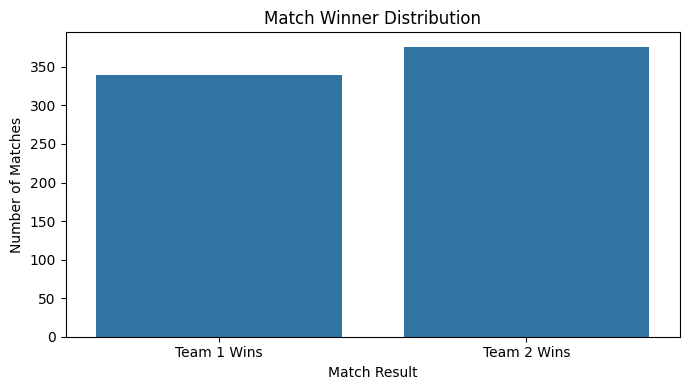

In [4]:

print("Winner label distribution:")
display(df["winner_label"].value_counts().sort_index())

print("\nWinner label percentage:")
display(
    df["winner_label"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .round(2)
)

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x="winner_label",
    order=[0, 1]
)

plt.xticks([0, 1], ["Team 1 Wins", "Team 2 Wins"])
plt.title("Match Winner Distribution")
plt.xlabel("Match Result")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()


In [5]:

print("Duplicate match IDs:", df["id"].duplicated().sum())

valid_labels = df["winner_label"].isin([0, 1]).all()

winner_matches = (
    ((df["winner_label"] == 0) & (df["winner"] == df["team_one"])) |
    ((df["winner_label"] == 1) & (df["winner"] == df["team_two"]))
)

print("Valid binary labels:", valid_labels)
print("Winner labels match winner names:", winner_matches.all())

print("\nSample phase validation:")
assert len(df) > 0
assert df["id"].is_unique
assert valid_labels
assert winner_matches.all()
assert df["match_date"].notna().any()

print("PASS")


Duplicate match IDs: 0
Valid binary labels: True
Winner labels match winner names: True

Sample phase validation:
PASS


In [6]:

# Sample phase: detailed data quality summary

quality_summary = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_percent": df.isna().mean() * 100
})

quality_summary = (
    quality_summary[quality_summary["missing_count"] > 0]
    .sort_values("missing_count", ascending=False)
)

print("Columns with missing values:", len(quality_summary))
display(quality_summary.head(15).round(2))

print("\nUnique Team 1 names:", df["team_one"].nunique())
print("Unique Team 2 names:", df["team_two"].nunique())

print("\nMatches with the same team on both sides:")
same_team = df["team_one"] == df["team_two"]
print(same_team.sum())

print("\nDate parsing problems:")
display(df.loc[df["match_date"].isna(), ["id", "date", "team_one", "team_two"]])


Columns with missing values: 47


,missing_count,missing_percent
t2_place_last_season,392,54.83
t1_place_last_season,384,53.71
t1_wins_last_20,202,28.25
t1_losses_last_20,202,28.25
t1_win_percent_last_20,202,28.25
t2_wins_last_20,201,28.11
t2_win_percent_last_20,201,28.11
t2_losses_last_20,201,28.11
t1_win_percent_vs_t2,191,26.71
t1_odds,119,16.64



Unique Team 1 names: 20
Unique Team 2 names: 20

Matches with the same team on both sides:
0

Date parsing problems:


,id,date,team_one,team_two
387,21352,NaN,Paris Eternal,London Spitfire


In [7]:

# Sample phase: historical statistics consistency checks

print("Historical match-count consistency:")

all_checks_passed = True

for team in ["t1", "t2"]:
    for period in ["season", "alltime"]:
        wins = df[f"{team}_wins_{period}"]
        losses = df[f"{team}_losses_{period}"]
        matches = df[f"{team}_matches_{period}"]

        valid_rows = wins.notna() & losses.notna() & matches.notna()

        inconsistent = (
            (wins[valid_rows] + losses[valid_rows])
            != matches[valid_rows]
        )

        count = int(inconsistent.sum())
        print(f"{team} {period}: {count} inconsistent rows")
        all_checks_passed &= (count == 0)

print("\nHistorical win-percentage ranges:")

for team in ["t1", "t2"]:
    for period in ["season", "alltime"]:
        column = f"{team}_win_percent_{period}"
        values = df[column].dropna()

        invalid = ((values < 0) | (values > 1)).sum()
        print(f"{column}: {invalid} invalid values")
        all_checks_passed &= (invalid == 0)

print("\nSample consistency validation:")
assert all_checks_passed, "Historical statistics failed validation."
print("PASS")


Historical match-count consistency:
t1 season: 0 inconsistent rows
t1 alltime: 0 inconsistent rows
t2 season: 0 inconsistent rows
t2 alltime: 0 inconsistent rows

Historical win-percentage ranges:
t1_win_percent_season: 0 invalid values
t1_win_percent_alltime: 0 invalid values
t2_win_percent_season: 0 invalid values
t2_win_percent_alltime: 0 invalid values

Sample consistency validation:
PASS



### Sample Phase Findings

The dataset contains 715 historical Overwatch League matches and 58 original columns, covering January 2018 through June 2020.

All available matches are retained during the Sample phase because the dataset is relatively small. This avoids discarding potentially useful historical records before the data quality checks.

The dataset includes 20 teams.

The target variable is `winner_label`:
- 0: Team 1 wins (339 matches)
- 1: Team 2 wins (376 matches)

The classes are relatively balanced, so a majority-class baseline will be useful for later evaluation.

Some historical performance features contain missing values, and one match has an invalid or missing date.

The Modify phase will determine how to handle missing values and the undated record before chronological train/test splitting.

Only information available before each match will be considered for model inputs. The winner columns, match outcomes, and other post-match information will be excluded from predictors.



## 2. Explore

### Objective

The Explore phase examines patterns in historical Overwatch League matches before building a prediction model.

This phase focuses on:

1. Match distribution across years.
2. Team performance and historical win rates.
3. Relationships between pre-match team statistics and match results.
4. Missing values in historical performance features.

The goal is to identify useful patterns and possible modeling issues.

These are exploratory observations, not evidence that a feature causes a team to win.


Matches by year:


,matches
match_date,
2018.0,262
2019.0,318
2020.0,134


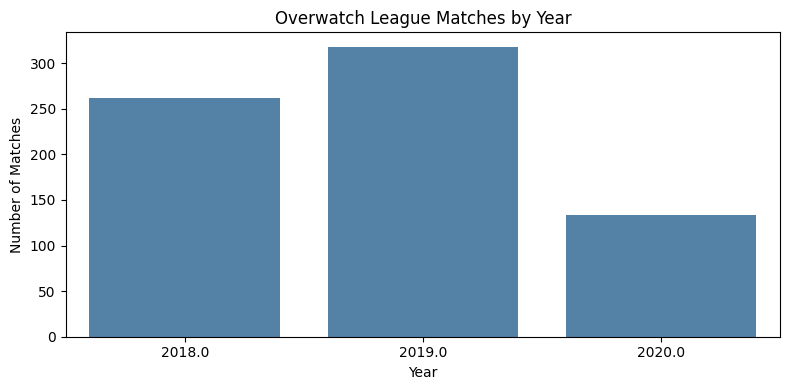

In [8]:

# Explore: match distribution by year

year_counts = (
    df["match_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

print("Matches by year:")
display(year_counts.rename("matches").to_frame())

plt.figure(figsize=(8, 4))
sns.barplot(
    x=year_counts.index.astype(str),
    y=year_counts.values,
    color="steelblue"
)

plt.title("Overwatch League Matches by Year")
plt.xlabel("Year")
plt.ylabel("Number of Matches")
plt.tight_layout()
plt.show()


Team performance summary:


,matches,wins,win_rate
team,,,
New York Excelsior,97,73,0.753
Vancouver Titans,50,36,0.720
San Francisco Shock,96,63,0.656
Philadelphia Fusion,96,59,0.615
London Spitfire,92,53,0.576
Hangzhou Spark,48,27,0.562
Los Angeles Gladiators,89,50,0.562
Los Angeles Valiant,89,49,0.551
Guangzhou Charge,44,24,0.545


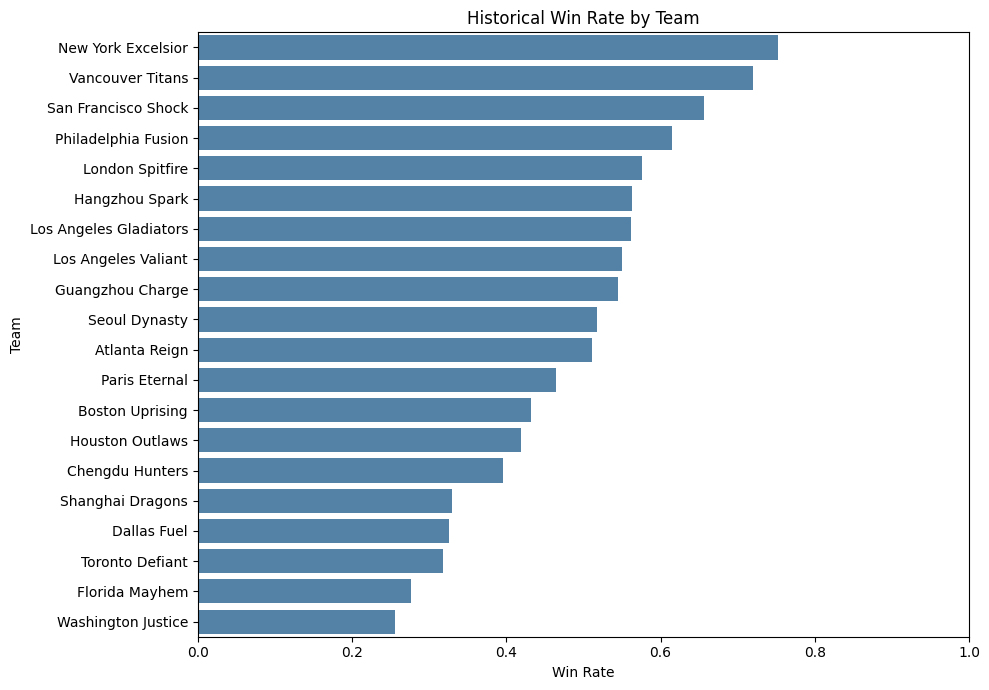

In [9]:

# Explore: team-level match performance

team1 = df[["team_one", "winner_label"]].copy()
team1.columns = ["team", "winner_label"]
team1["win"] = (team1["winner_label"] == 0).astype(int)

team2 = df[["team_two", "winner_label"]].copy()
team2.columns = ["team", "winner_label"]
team2["win"] = (team2["winner_label"] == 1).astype(int)

team_results = pd.concat(
    [team1[["team", "win"]], team2[["team", "win"]]],
    ignore_index=True
)

team_summary = (
    team_results.groupby("team")
    .agg(matches=("win", "size"), wins=("win", "sum"))
)

team_summary["win_rate"] = (
    team_summary["wins"] / team_summary["matches"]
)

team_summary = team_summary.sort_values(
    "win_rate", ascending=False
)

print("Team performance summary:")
display(team_summary.round(3))

plt.figure(figsize=(10, 7))
sns.barplot(
    data=team_summary.reset_index(),
    x="win_rate",
    y="team",
    color="steelblue"
)

plt.title("Historical Win Rate by Team")
plt.xlabel("Win Rate")
plt.ylabel("Team")
plt.xlim(0, 1)
plt.tight_layout()
plt.show()


Records with both recent-form values: 647


,matches,team1_win_rate
recent_form_group,,
Team 2 better recent form,209,0.258
Similar recent form,259,0.456
Team 1 better recent form,179,0.732


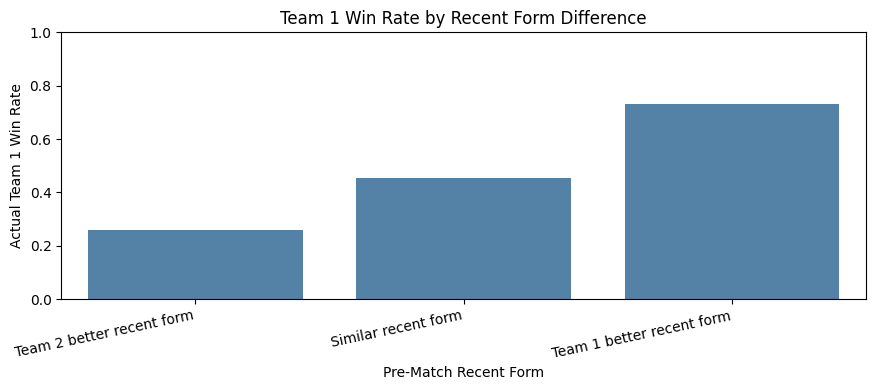

In [10]:

# Explore: pre-match recent-form advantage

form_data = df[
    [
        "t1_win_percent_last_5",
        "t2_win_percent_last_5",
        "winner_label"
    ]
].dropna().copy()

form_data["recent_win_rate_diff"] = (
    form_data["t1_win_percent_last_5"]
    - form_data["t2_win_percent_last_5"]
)

form_data["team1_won"] = (
    form_data["winner_label"] == 0
).astype(int)

form_data["recent_form_group"] = pd.cut(
    form_data["recent_win_rate_diff"],
    bins=[-1.01, -0.2, 0.2, 1.01],
    labels=[
        "Team 2 better recent form",
        "Similar recent form",
        "Team 1 better recent form"
    ]
)

form_summary = (
    form_data.groupby(
        "recent_form_group",
        observed=False
    )
    .agg(
        matches=("team1_won", "size"),
        team1_win_rate=("team1_won", "mean")
    )
)

print("Records with both recent-form values:", len(form_data))
display(form_summary.round(3))

plt.figure(figsize=(9, 4))
sns.barplot(
    data=form_summary.reset_index(),
    x="recent_form_group",
    y="team1_win_rate",
    color="steelblue"
)

plt.title("Team 1 Win Rate by Recent Form Difference")
plt.xlabel("Pre-Match Recent Form")
plt.ylabel("Actual Team 1 Win Rate")
plt.ylim(0, 1)
plt.xticks(rotation=12, ha="right")
plt.tight_layout()
plt.show()


Missing percentage in historical performance features:


,missing_percent
t1_win_percent_last_20,28.25
t2_win_percent_last_20,28.11
t1_win_percent_vs_t2,26.71
t2_win_percent_last_10,14.27
t1_win_percent_last_10,14.13
t2_win_percent_last_5,7.41
t1_win_percent_last_5,7.13
t1_win_percent_last_3,4.90
t2_win_percent_last_3,4.20
t2_win_percent_alltime,0.14


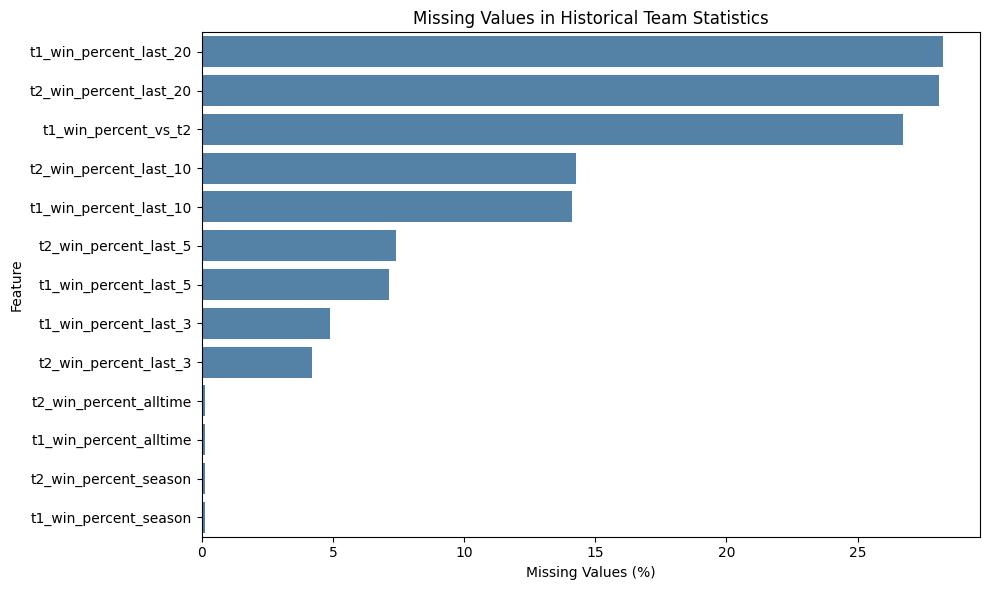

In [11]:

# Explore: missing values in pre-match performance features

history_features = [
    "t1_win_percent_season",
    "t2_win_percent_season",
    "t1_win_percent_alltime",
    "t2_win_percent_alltime",
    "t1_win_percent_last_3",
    "t2_win_percent_last_3",
    "t1_win_percent_last_5",
    "t2_win_percent_last_5",
    "t1_win_percent_last_10",
    "t2_win_percent_last_10",
    "t1_win_percent_last_20",
    "t2_win_percent_last_20",
    "t1_win_percent_vs_t2"
]

missing_history = (
    df[history_features]
    .isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

print("Missing percentage in historical performance features:")
display(missing_history.round(2).rename("missing_percent").to_frame())

plt.figure(figsize=(10, 6))
sns.barplot(
    x=missing_history.values,
    y=missing_history.index,
    color="steelblue"
)

plt.title("Missing Values in Historical Team Statistics")
plt.xlabel("Missing Values (%)")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()


Recent form and match outcomes by year:


,year,recent_form_group,matches,team1_win_rate
0,2018,Team 2 better,68,0.191
1,2018,Similar form,95,0.474
2,2018,Team 1 better,67,0.731
3,2019,Team 2 better,97,0.278
4,2019,Similar form,112,0.438
5,2019,Team 1 better,74,0.743
6,2020,Team 2 better,44,0.318
7,2020,Similar form,52,0.462
8,2020,Team 1 better,38,0.711


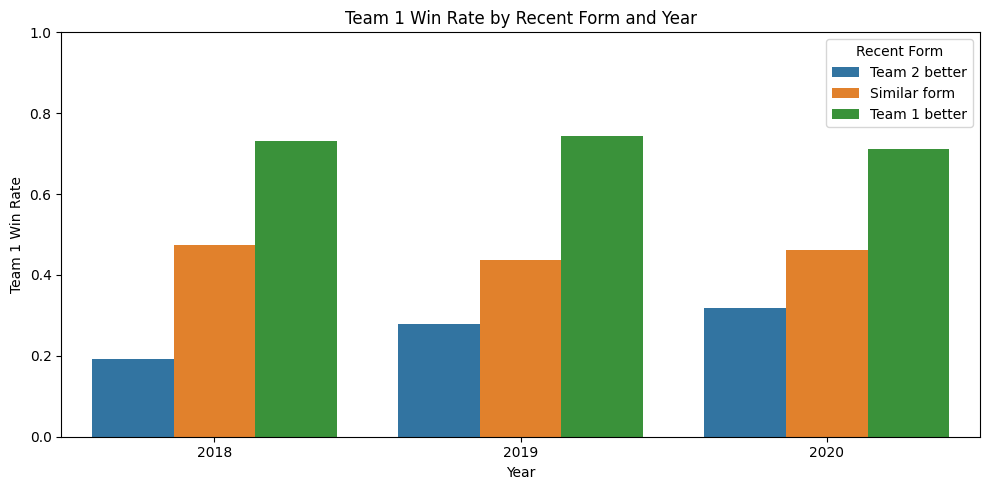

In [12]:

# Explore: recent form and match results by year

yearly_form = df[
    [
        "match_date",
        "t1_win_percent_last_5",
        "t2_win_percent_last_5",
        "winner_label"
    ]
].dropna().copy()

yearly_form["year"] = yearly_form["match_date"].dt.year.astype(int)

yearly_form["recent_win_rate_diff"] = (
    yearly_form["t1_win_percent_last_5"]
    - yearly_form["t2_win_percent_last_5"]
)

yearly_form["recent_form_group"] = pd.cut(
    yearly_form["recent_win_rate_diff"],
    bins=[-1.01, -0.2, 0.2, 1.01],
    labels=[
        "Team 2 better",
        "Similar form",
        "Team 1 better"
    ]
)

yearly_form["team1_won"] = (
    yearly_form["winner_label"] == 0
).astype(int)

yearly_summary = (
    yearly_form.groupby(
        ["year", "recent_form_group"],
        observed=False
    )
    .agg(
        matches=("team1_won", "size"),
        team1_win_rate=("team1_won", "mean")
    )
    .reset_index()
)

print("Recent form and match outcomes by year:")
display(yearly_summary.round(3))

plt.figure(figsize=(10, 5))

sns.barplot(
    data=yearly_summary,
    x="year",
    y="team1_win_rate",
    hue="recent_form_group"
)

plt.title("Team 1 Win Rate by Recent Form and Year")
plt.xlabel("Year")
plt.ylabel("Team 1 Win Rate")
plt.ylim(0, 1)
plt.legend(title="Recent Form")
plt.tight_layout()
plt.show()



### Explore - Findings

The dataset contains matches from 2018 to 2020. The highest number of recorded matches was in 2019, with 318 matches.

Team performance varied across the dataset. New York Excelsior had the highest overall win rate at 75.3%, followed by Vancouver Titans at 72.0%.

Recent team performance showed a clear relationship with match results.

Among the 647 matches with available recent five-match statistics:

- When Team 1 had better recent form, it won 73.2% of the matches.
- When both teams had similar recent form, Team 1 won 45.6%.
- When Team 2 had better recent form, Team 1 won only 25.8%.

This suggests that recent team performance may be useful for predicting match winners. However, the result is exploratory and does not establish predictive performance.

Missing values were more common in longer historical windows. The recent 20-match win-rate features had about 28% missing values, while recent 5-match features had about 7%.

The Modify phase will address missing values, select appropriate pre-match features, and prepare a chronological train/test split.

Overall team win rates calculated from the complete dataset will remain descriptive only and will not be used directly as model inputs.

### Year-by-Year Recent Form Analysis

The relationship between recent team performance and match outcomes was also examined separately for 2018, 2019, and 2020.

When Team 1 had better recent form, its actual win rates were:

- 2018: 73.1%
- 2019: 74.3%
- 2020: 71.1%

When Team 2 had better recent form, Team 1's win rates were lower:

- 2018: 19.1%
- 2019: 27.8%
- 2020: 31.8%

A similar pattern appeared in all three years.

This supports the earlier observation that recent team performance is associated with match outcomes.

However, the groups contain different numbers of matches, and the results do not guarantee future prediction performance.



## 3. Modify

### Objective

The Modify phase prepares the historical match data for machine learning.

This phase focuses on:

1. Removing records without a valid match date.
2. Selecting historical team performance features.
3. Creating features that compare the two teams.
4. Splitting the data chronologically into training and test sets.
5. Preparing preprocessing steps for missing values and feature scaling.

The target is `winner_label`, where 0 means Team 1 wins and 1 means Team 2 wins.

Match winners, betting odds, and other information unavailable before a match will not be used as predictors.

Preprocessing rules will be learned from the training data only to avoid data leakage.


In [13]:

# Modify: prepare chronologically ordered matches

model_df = df.dropna(subset=["match_date"]).copy()

model_df = (
    model_df.sort_values(["match_date", "id"])
    .reset_index(drop=True)
)

print("Original records:", len(df))
print("Records excluded due to missing date:", len(df) - len(model_df))
print("Records available for modeling:", len(model_df))

print("\nDate range:")
print(model_df["match_date"].min(), "to", model_df["match_date"].max())

print("\nChronological order:", model_df["match_date"].is_monotonic_increasing)

assert model_df["match_date"].notna().all()
assert model_df["match_date"].is_monotonic_increasing

print("PASS")


Original records: 715
Records excluded due to missing date: 1
Records available for modeling: 714

Date range:
2018-01-11 00:00:00 to 2020-06-14 00:00:00

Chronological order: True
PASS


In [14]:

# Modify: create pre-match comparison features

feature_pairs = {
    "season_win_rate_diff": (
        "t1_win_percent_season",
        "t2_win_percent_season"
    ),
    "alltime_win_rate_diff": (
        "t1_win_percent_alltime",
        "t2_win_percent_alltime"
    ),
    "recent_5_win_rate_diff": (
        "t1_win_percent_last_5",
        "t2_win_percent_last_5"
    ),
    "season_matches_diff": (
        "t1_matches_season",
        "t2_matches_season"
    ),
    "alltime_matches_diff": (
        "t1_matches_alltime",
        "t2_matches_alltime"
    )
}

feature_columns = []

for new_feature, (team1_col, team2_col) in feature_pairs.items():
    model_df[new_feature] = (
        model_df[team1_col] - model_df[team2_col]
    )
    feature_columns.append(new_feature)

X = model_df[feature_columns].copy()
y = model_df["winner_label"].astype(int).copy()

print("Selected features:")
print(feature_columns)

print("\nFeature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values in selected features:")
display(X.isna().sum().to_frame("missing_count"))

print("\nFeature sample:")
display(X.head())


Selected features:
['season_win_rate_diff', 'alltime_win_rate_diff', 'recent_5_win_rate_diff', 'season_matches_diff', 'alltime_matches_diff']

Feature matrix shape: (714, 5)
Target shape: (714,)

Missing values in selected features:


,missing_count
season_win_rate_diff,0
alltime_win_rate_diff,0
recent_5_win_rate_diff,67
season_matches_diff,0
alltime_matches_diff,0



Feature sample:


,season_win_rate_diff,alltime_win_rate_diff,recent_5_win_rate_diff,season_matches_diff,alltime_matches_diff
0,0.0,0.0,NaN,0.0,0.0
1,0.0,0.0,NaN,0.0,0.0
2,0.0,0.0,NaN,0.0,0.0
3,0.0,0.0,NaN,0.0,0.0
4,0.0,0.0,NaN,0.0,0.0


In [15]:

# Modify: chronological train/test split

unique_dates = np.sort(model_df["match_date"].unique())

split_index = int(len(unique_dates) * 0.8)
test_start_date = unique_dates[split_index]

train_mask = model_df["match_date"] < test_start_date
test_mask = model_df["match_date"] >= test_start_date

X_train = X.loc[train_mask].copy()
X_test = X.loc[test_mask].copy()

y_train = y.loc[train_mask].copy()
y_test = y.loc[test_mask].copy()

train_dates = model_df.loc[train_mask, "match_date"]
test_dates = model_df.loc[test_mask, "match_date"]

print("Training records:", len(X_train))
print("Test records:", len(X_test))

print("\nTraining date range:")
print(train_dates.min(), "to", train_dates.max())

print("\nTest date range:")
print(test_dates.min(), "to", test_dates.max())

print("\nTraining target distribution:")
display(y_train.value_counts().sort_index())

print("\nTest target distribution:")
display(y_test.value_counts().sort_index())

assert len(X_train) > 0
assert len(X_test) > 0
assert train_dates.max() < test_dates.min()

print("\nChronological split validation: PASS")


Training records: 561
Test records: 153

Training date range:
2018-01-11 00:00:00 to 2019-08-25 00:00:00

Test date range:
2019-08-26 00:00:00 to 2020-06-14 00:00:00

Training target distribution:


,count
winner_label,
0,268
1,293



Test target distribution:


,count
winner_label,
0,71
1,82



Chronological split validation: PASS


In [16]:

# Modify: preprocessing pipeline

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

preprocessor = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Processed training shape:", X_train_processed.shape)
print("Processed test shape:", X_test_processed.shape)

print("\nRemaining NaN values:")
print("Training:", np.isnan(X_train_processed).sum())
print("Test:", np.isnan(X_test_processed).sum())

print("\nRemaining infinite values:")
print("Training:", np.isinf(X_train_processed).sum())
print("Test:", np.isinf(X_test_processed).sum())

assert np.isfinite(X_train_processed).all()
assert np.isfinite(X_test_processed).all()

print("\nPreprocessing validation: PASS")


Processed training shape: (561, 5)
Processed test shape: (153, 5)

Remaining NaN values:
Training: 0
Test: 0

Remaining infinite values:
Training: 0
Test: 0

Preprocessing validation: PASS


In [17]:

# Modify: prepare a reusable model pipeline

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression

baseline_pipeline = Pipeline([
    ("preprocessing", clone(preprocessor)),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=42
    ))
])

print("Pipeline steps:")
print(list(baseline_pipeline.named_steps.keys()))

print("\nPreprocessing steps:")
print(
    list(
        baseline_pipeline.named_steps["preprocessing"]
        .named_steps.keys()
    )
)

assert list(baseline_pipeline.named_steps.keys()) == [
    "preprocessing", "classifier"
]

print("\nReusable pipeline validation: PASS")


Pipeline steps:
['preprocessing', 'classifier']

Preprocessing steps:
['imputer', 'scaler']

Reusable pipeline validation: PASS


In [18]:

# Modify: final feature and chronological split validation

print("Selected model features:")
display(pd.DataFrame({"feature": feature_columns}))

# Check that no outcome or betting information is included
forbidden_columns = {
    "winner",
    "winner_label",
    "t1_odds",
    "t2_odds"
}

assert not forbidden_columns.intersection(feature_columns)

# Check feature consistency
assert X_train.columns.tolist() == feature_columns
assert X_test.columns.tolist() == feature_columns

# Check chronological separation
assert train_dates.max() < test_dates.min()

# Check that both classes exist in each split
assert set(y_train.unique()) == {0, 1}
assert set(y_test.unique()) == {0, 1}

split_summary = pd.DataFrame({
    "split": ["Train", "Test"],
    "records": [len(X_train), len(X_test)],
    "team1_wins": [
        int((y_train == 0).sum()),
        int((y_test == 0).sum())
    ],
    "team2_wins": [
        int((y_train == 1).sum()),
        int((y_test == 1).sum())
    ],
    "start_date": [
        train_dates.min(),
        test_dates.min()
    ],
    "end_date": [
        train_dates.max(),
        test_dates.max()
    ]
})

print("\nChronological split summary:")
display(split_summary)

print("\nFinal Modify validation: PASS")


Selected model features:


,feature
0,season_win_rate_diff
1,alltime_win_rate_diff
2,recent_5_win_rate_diff
3,season_matches_diff
4,alltime_matches_diff



Chronological split summary:


,split,records,team1_wins,team2_wins,start_date,end_date
0,Train,561,268,293,2018-01-11,2019-08-25
1,Test,153,71,82,2019-08-26,2020-06-14



Final Modify validation: PASS



### Modify - Initial Findings

The Modify phase prepared the historical match data for machine learning.

One record without a valid match date was excluded because chronological evaluation requires a known match date.

Five comparison features were created using differences between Team 1 and Team 2:

- Season win-rate difference
- All-time win-rate difference
- Recent five-match win-rate difference
- Season match-count difference
- All-time match-count difference

These features use historical team statistics rather than final match results.

The data was divided chronologically into training and test sets, keeping earlier matches for training and later matches for evaluation.

A preprocessing pipeline was created using median imputation and standard scaling.

The preprocessing parameters were learned from the training data only.

The original dataset's historical statistics have not been independently reconstructed, so their pre-match timing remains an important limitation.

A reusable model pipeline was also prepared by combining preprocessing with Logistic Regression.

This structure will allow preprocessing to be fitted separately within each training fold during cross-validation.

The pipeline has been defined but has not yet been trained.

A final validation confirmed that the selected features exclude the target and betting odds columns.

The training and test sets have matching feature columns, both contain the two target classes, and their date ranges do not overlap.

The chronological split and selected feature checks passed.



## 4. Model

### Objective

The Model phase compares machine learning algorithms for predicting Overwatch League match winners.

Two classification models are evaluated:

1. Logistic Regression
2. Random Forest

The models use five pre-match comparison features created during the Modify phase.

Training and evaluation follow the chronological order of matches.

TimeSeriesSplit cross-validation is used within the training data to evaluate model performance without training on later matches and validating on earlier matches.

Accuracy and F1-score are used to compare models.

Preprocessing is included inside each model pipeline to avoid leakage during cross-validation.


In [19]:

# Model: create classification pipelines

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import TimeSeriesSplit, cross_validate
from sklearn.metrics import accuracy_score, f1_score

models = {
    "Logistic Regression": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", LogisticRegression(
            max_iter=1000,
            random_state=42
        ))
    ]),
    "Random Forest": Pipeline([
        ("preprocessing", clone(preprocessor)),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            min_samples_leaf=3,
            random_state=42,
            n_jobs=-1
        ))
    ])
}

print("Models prepared:")
for name, model in models.items():
    print(name, ":", list(model.named_steps.keys()))


Models prepared:
Logistic Regression : ['preprocessing', 'classifier']
Random Forest : ['preprocessing', 'classifier']


In [20]:

# Model: chronological cross-validation

tscv = TimeSeriesSplit(n_splits=5)

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=tscv,
        scoring={
            "accuracy": "accuracy",
            "f1": "f1"
        },
        n_jobs=-1
    )

    cv_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std()
    })

cv_summary = pd.DataFrame(cv_results).sort_values(
    "F1 Mean",
    ascending=False
)

print("TimeSeriesSplit Cross-Validation Results:")
display(cv_summary.round(4))


TimeSeriesSplit Cross-Validation Results:


,Model,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std
0,Logistic Regression,0.6452,0.0490,0.6749,0.0406
1,Random Forest,0.6086,0.0411,0.6091,0.0365


In [21]:

# Model: select and train the final model

best_model_name = cv_summary.iloc[0]["Model"]

final_model = clone(models[best_model_name])
final_model.fit(X_train, y_train)

print("Selected model:", best_model_name)
print("Training records:", len(X_train))
print("Selected features:", feature_columns)
print("Model training completed")


Selected model: Logistic Regression
Training records: 561
Selected features: ['season_win_rate_diff', 'alltime_win_rate_diff', 'recent_5_win_rate_diff', 'season_matches_diff', 'alltime_matches_diff']
Model training completed


In [22]:

# Model: check date boundaries in cross-validation

cv_date_checks = []

for fold, (train_idx, val_idx) in enumerate(
    tscv.split(X_train), start=1
):
    fold_train_dates = train_dates.iloc[train_idx]
    fold_val_dates = train_dates.iloc[val_idx]

    no_date_overlap = (
        fold_train_dates.max() < fold_val_dates.min()
    )

    cv_date_checks.append({
        "Fold": fold,
        "Train End": fold_train_dates.max(),
        "Validation Start": fold_val_dates.min(),
        "No Date Overlap": no_date_overlap
    })

cv_date_check_df = pd.DataFrame(cv_date_checks)

print("Cross-validation date boundary checks:")
display(cv_date_check_df)

print(
    "\nAll folds have separate dates:",
    cv_date_check_df["No Date Overlap"].all()
)


Cross-validation date boundary checks:


,Fold,Train End,Validation Start,No Date Overlap
0,1,2018-03-10,2018-03-10,False
1,2,2018-05-17,2018-05-17,False
2,3,2019-02-22,2019-02-23,True
3,4,2019-04-19,2019-04-19,False
4,5,2019-06-29,2019-06-29,False



All folds have separate dates: False


In [23]:

# Model: date-safe cross-validation

unique_train_dates = np.sort(train_dates.unique())
date_tscv = TimeSeriesSplit(n_splits=5)

date_safe_splits = []

for train_date_idx, val_date_idx in date_tscv.split(unique_train_dates):
    fold_train_dates = unique_train_dates[train_date_idx]
    fold_val_dates = unique_train_dates[val_date_idx]

    train_idx = np.flatnonzero(
        train_dates.isin(fold_train_dates).to_numpy()
    )
    val_idx = np.flatnonzero(
        train_dates.isin(fold_val_dates).to_numpy()
    )

    assert train_dates.iloc[train_idx].max() < train_dates.iloc[val_idx].min()

    date_safe_splits.append((train_idx, val_idx))

# Re-evaluate both models using date-safe folds
revised_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=date_safe_splits,
        scoring={"accuracy": "accuracy", "f1": "f1"},
        n_jobs=-1
    )

    revised_results.append({
        "Model": name,
        "Accuracy Mean": scores["test_accuracy"].mean(),
        "Accuracy Std": scores["test_accuracy"].std(),
        "F1 Mean": scores["test_f1"].mean(),
        "F1 Std": scores["test_f1"].std()
    })

cv_summary = pd.DataFrame(revised_results).sort_values(
    "F1 Mean", ascending=False
)

print("Revised date-safe cross-validation results:")
display(cv_summary.round(4))

print("\nDate-safe folds:", len(date_safe_splits))
print("Date overlap: none")


Revised date-safe cross-validation results:


,Model,Accuracy Mean,Accuracy Std,F1 Mean,F1 Std
0,Logistic Regression,0.6629,0.0721,0.6891,0.0599
1,Random Forest,0.6207,0.0269,0.6330,0.0240



Date-safe folds: 5
Date overlap: none


In [24]:

# Model: update final model using revised CV results

best_model_name = cv_summary.iloc[0]["Model"]

final_model = clone(models[best_model_name])
final_model.fit(X_train, y_train)

print("Final selected model:", best_model_name)
print("Training records:", len(X_train))
print("Final training completed")


Final selected model: Logistic Regression
Training records: 561
Final training completed



### Model - Initial Findings

Two classification pipelines were prepared: Logistic Regression and Random Forest.

Both models use the same five historical team comparison features.

Five-fold TimeSeriesSplit cross-validation was used to compare Accuracy and F1-score on the training data.

Preprocessing was included inside the pipelines so that imputation and scaling were fitted separately within each training fold.

The model with the highest mean cross-validation F1-score was selected and trained using the complete training set.

The held-out test set has not been used for model selection. Final performance will be evaluated during the Assess phase.

### Cross-Validation Revision

The initial row-based TimeSeriesSplit validation found that four of five folds shared dates between training and validation.

To address this issue, cross-validation was revised to split by unique match dates, ensuring that all matches on the same date remain in the same fold.

Both models were re-evaluated using the revised date-safe folds. The final model was selected again based on the updated mean F1-score.



## 5. Assess

### Objective

The Assess phase evaluates the selected model on the held-out test set.

This phase focuses on:

1. Measuring Accuracy, Precision, Recall, and F1-score.
2. Examining correct and incorrect predictions with a confusion matrix.
3. Comparing the model against a simple majority-class baseline.
4. Discussing the model's limitations.

The test set contains later matches that were not used for model selection.


In [25]:

# Assess: evaluate the selected model on unseen test data

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_pred = final_model.predict(X_test)

test_metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1-score": f1_score(y_test, y_pred, zero_division=0)
}

print("Selected model:", best_model_name)
print("Test records:", len(y_test))

print("\nHeld-out test performance:")
display(
    pd.DataFrame([test_metrics], index=[best_model_name]).round(4)
)

print("\nClassification report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Team 1 wins", "Team 2 wins"],
    zero_division=0
))


Selected model: Logistic Regression
Test records: 153

Held-out test performance:


,Accuracy,Precision,Recall,F1-score
Logistic Regression,0.6536,0.6629,0.7195,0.6901



Classification report:
              precision    recall  f1-score   support

 Team 1 wins       0.64      0.58      0.61        71
 Team 2 wins       0.66      0.72      0.69        82

    accuracy                           0.65       153
   macro avg       0.65      0.65      0.65       153
weighted avg       0.65      0.65      0.65       153



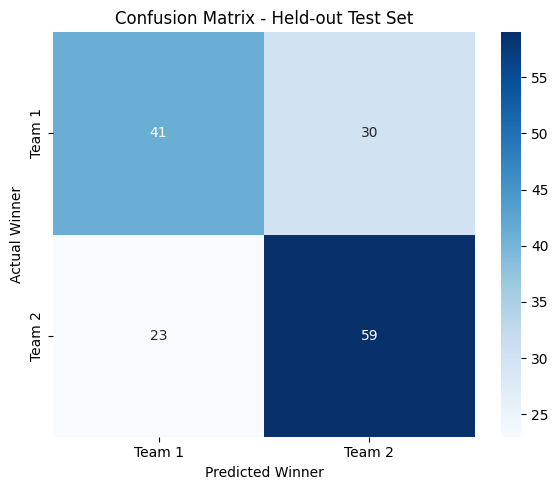

Correct predictions: 100
Incorrect predictions: 53


In [26]:

# Assess: visualize prediction errors

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Team 1", "Team 2"],
    yticklabels=["Team 1", "Team 2"]
)

plt.title("Confusion Matrix - Held-out Test Set")
plt.xlabel("Predicted Winner")
plt.ylabel("Actual Winner")
plt.tight_layout()
plt.show()

print("Correct predictions:", int(np.trace(cm)))
print("Incorrect predictions:", int(cm.sum() - np.trace(cm)))


In [27]:

# Assess: compare with a simple majority-class baseline

majority_class = y_train.value_counts().idxmax()

baseline_pred = np.full(
    len(y_test),
    majority_class,
    dtype=int
)

comparison = pd.DataFrame([
    {
        "Model": "Majority Baseline",
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "F1-score": f1_score(
            y_test, baseline_pred, zero_division=0
        )
    },
    {
        "Model": best_model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "F1-score": f1_score(
            y_test, y_pred, zero_division=0
        )
    }
])

print("Majority class in training:", majority_class)
print("\nBaseline comparison:")
display(comparison.round(4))


Majority class in training: 1

Baseline comparison:


,Model,Accuracy,F1-score
0,Majority Baseline,0.5359,0.6979
1,Logistic Regression,0.6536,0.6901


In [28]:

# Assess: compare both classes equally

from sklearn.metrics import balanced_accuracy_score

fair_comparison = pd.DataFrame([
    {
        "Model": "Majority Baseline",
        "Accuracy": accuracy_score(y_test, baseline_pred),
        "Macro F1": f1_score(
            y_test, baseline_pred, average="macro",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, baseline_pred
        )
    },
    {
        "Model": best_model_name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(
            y_test, y_pred, average="macro",
            zero_division=0
        ),
        "Balanced Accuracy": balanced_accuracy_score(
            y_test, y_pred
        )
    }
])

print("Evaluation across both winner classes:")
display(fair_comparison.round(4))


Evaluation across both winner classes:


,Model,Accuracy,Macro F1,Balanced Accuracy
0,Majority Baseline,0.5359,0.3489,0.5000
1,Logistic Regression,0.6536,0.6487,0.6485



### Assess - Initial Findings

The final selected model was evaluated on 153 held-out test matches.

Accuracy, Precision, Recall, and F1-score were calculated. A confusion matrix was used to examine correct and incorrect winner predictions.

The selected model was also compared with a baseline that always predicts the most common winner label in the training set.

The dataset is limited to historical matches from 2018 to 2020. Also, the timing of the provided historical statistics has not been independently verified, so the results should not be treated as proven real-world forecasting performance.

The Logistic Regression model correctly predicted 100 of 153 test matches, achieving 65.36% accuracy.

Its F1-score for Team 2 wins was 0.6901. Although this was slightly lower than the majority baseline's F1-score of 0.6979, the model achieved higher accuracy.

Because the majority baseline always predicts Team 2 wins, Macro F1 and Balanced Accuracy were added to evaluate performance across both winner classes.



### Prediction Errors and Final Interpretation

The confusion matrix showed that Logistic Regression correctly predicted 41 Team 1 wins and 59 Team 2 wins.

It incorrectly predicted Team 2 for 30 matches won by Team 1, and incorrectly predicted Team 1 for 23 matches won by Team 2.

The model achieved a Macro F1-score of 0.6487 and Balanced Accuracy of 0.6485, compared with 0.3489 and 0.5000 for the majority baseline.

These results show that Logistic Regression performed better than the simple baseline when both winner classes were considered equally.

However, 53 of 153 matches were predicted incorrectly. The model provides a useful baseline for match-winner prediction, but its accuracy is limited.

The results also depend on historical statistics supplied by the dataset, whose pre-match availability was not independently verified.



## 6. Conclusion

This project followed all five phases of SEMMA to predict Overwatch League match winners using historical team performance.

Logistic Regression performed better than Random Forest in date-safe cross-validation and was selected as the final model.

On the held-out test set of 153 matches, Logistic Regression achieved 65.36% accuracy and a Macro F1-score of 0.6487.

It outperformed the majority-class baseline on both metrics.

The results suggest that historical team performance can provide useful information for match-winner prediction.

However, the model made 53 incorrect predictions, and the dataset covers only historical matches from 2018 to 2020.

The timing of the supplied historical statistics was not independently verified, so the results should be interpreted with caution.

Overall, this project demonstrated the SEMMA process, from exploring historical match data to evaluating a classification model.
